# **Natural Language Processing Analysis of Consumer Complaint Narratives Using Text Mining and Topic Modelling**

# **Kaggle API**

In [1]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 7.9 MB/s eta 0:00:00


# **Configure Kaggle API**

In [ ]:
import os

# Upload kaggle.json to /content before running this cell
os.makedirs('/root/.kaggle', exist_ok=True)
!cp /content/kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

# **Downloading Consumer Complaint Dataset**

In [3]:
!kaggle datasets download -d selener/consumer-complaint-database

Dataset URL: https://www.kaggle.com/datasets/selener/consumer-complaint-database
License(s): U.S. Government Works
100% 176M/176M [00:10<00:00, 17.7MB/s]



In [4]:
import zipfile

zip_file="/content/consumer-complaint-database.zip"


with zipfile.ZipFile(zip_file,'r') as zip_ref:
    zip_ref.extractall("/content/complaint_data")


print(os.listdir("/content/complaint_data"))

['rows.csv']


# **Loading Dataset**

In [5]:
import pandas as pd

df = pd.read_csv(
    "/content/complaint_data/rows.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1282355, 18)


,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,05/10/2019,Checking or savings account,Checking account,Managing an account,Problem using a debit or ATM card,NaN,NaN,NAVY FEDERAL CREDIT UNION,FL,328XX,Older American,NaN,Web,05/10/2019,In progress,Yes,NaN,3238275
1,05/10/2019,Checking or savings account,Other banking product or service,Managing an account,Deposits and withdrawals,NaN,NaN,BOEING EMPLOYEES CREDIT UNION,WA,98204,NaN,NaN,Referral,05/10/2019,Closed with explanation,Yes,NaN,3238228
2,05/10/2019,Debt collection,Payday loan debt,Communication tactics,Frequent or repeated calls,NaN,NaN,CURO Intermediate Holdings,TX,751XX,NaN,NaN,Web,05/10/2019,Closed with explanation,Yes,NaN,3237964
3,05/10/2019,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Old information reappears or never goes away,NaN,NaN,Ad Astra Recovery Services Inc,LA,708XX,NaN,NaN,Web,05/10/2019,Closed with explanation,Yes,NaN,3238479
4,05/10/2019,Checking or savings account,Checking account,Managing an account,Banking errors,NaN,NaN,ALLY FINANCIAL INC.,AZ,85205,NaN,NaN,Postal mail,05/10/2019,In progress,Yes,NaN,3238460


# **Checking Dataset Structure**

In [6]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (1282355, 18)

Columns:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Consumer disputed?', 'Complaint ID']


# **Select only complaint narratives**

In [7]:
text_column = "Consumer complaint narrative"

data = df[[text_column]].copy()

print("Rows before removing missing narratives:", len(data))

data = data.dropna(subset=[text_column])

print("Rows after removing missing narratives:", len(data))

data.head()

Rows before removing missing narratives: 1282355
Rows after removing missing narratives: 383564


,Consumer complaint narrative
29904,The Summer of XX/XX/2018 I was denied a mortga...
30629,There are many mistakes appear in my report wi...
30735,There are many mistakes appear in my report wi...
30795,There are many mistakes appear in my report wi...
30807,There are many mistakes appear in my report wi...


# **Duplicates Removal**

In [8]:
data = data.drop_duplicates(subset=[text_column])

print("Rows after removing duplicates:", len(data))

Rows after removing duplicates: 366945


# **Random Sampling of 30,000 Complaints**

In [9]:
sample_size = min(30000, len(data))

data = data.sample(
    n=sample_size,
    random_state=42
).reset_index(drop=True)

print("Final sample size:", len(data))

data.head()

Final sample size: 30000


,Consumer complaint narrative
0,I live in the city of XXXX Maryland. The City ...
1,My account balance on my capital one checking ...
2,multiple attempts to collect on a debt that ha...
3,I have informed Transunion that the Alabama XX...
4,I pulled my credit report on XX/XX/2018 and no...


# **Basic dataset information**

In [10]:
print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print("Original dataset rows:", df.shape[0])
print("Original dataset columns:", df.shape[1])
print("Selected text column:", text_column)
print("Final NLP sample:", len(data))

print("\nMissing values in selected sample:")
print(data.isnull().sum())

DATASET SUMMARY
Original dataset rows: 1282355
Original dataset columns: 18
Selected text column: Consumer complaint narrative
Final NLP sample: 30000

Missing values in selected sample:
Consumer complaint narrative    0
dtype: int64


# **text-length statistics**

In [11]:
data["character_count"] = data[text_column].astype(str).str.len()
data["word_count"] = data[text_column].astype(str).str.split().str.len()

print(data[["character_count", "word_count"]].describe().round(2))

       character_count  word_count
count         30000.00    30000.00
mean           1109.90      201.95
std            1147.35      206.35
min              11.00        2.00
25%             416.00       76.00
50%             776.00      141.00
75%            1406.00      257.00
max           30016.00     5264.00


# **original complaint examples**

In [12]:
pd.set_option("display.max_colwidth", 250)

print("Example complaint narratives:\n")

for i in range(3):
    print(f"\nComplaint {i+1}")
    print("-" * 50)
    print(data.loc[i, text_column])

Example complaint narratives:


Complaint 1
--------------------------------------------------
I live in the city of XXXX Maryland. The City offers tax incentives for homeowners with a certain income. I qualify for a homeowners credit tax credit and a special credit because of my income. I currently have an impound account with my mortgage company to cover my taxes. However my mortgage company didn't understand how the program works and did not apply the money to my account so even though my taxes were paid almost in full with the exception of {$400.00} yes, the mortgage company continue to make me pay money into my impound account. This is been going on for 2 years now. Recently I fell behind on my payments due to unemployment. The mortgage company begin foreclosure proceedings but didn't tell me that I had money and an impound account that could be used because my taxes have been paid. It wasn't until after I caught up with my payments and realize that my taxes were paid I question t

# **NLP libraries**

In [13]:
!pip -q install nltk wordcloud

In [14]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF

from wordcloud import WordCloud

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

# **stopwords and lemmatizer**

In [15]:
stop_words = set(stopwords.words("english"))

custom_stopwords = {
    "xxxx", "xxx", "xx",
    "would", "could", "also",
    "one", "get", "said",
    "told", "please"
}

stop_words.update(custom_stopwords)

lemmatizer = WordNetLemmatizer()

print("Number of stopwords:", len(stop_words))

Number of stopwords: 209


# **Text Preprocessing and Cleaning Function**

In [16]:
def preprocess_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove repeated spaces
    text = re.sub(r"\s+", " ", text).strip()

    words = text.split()

    clean_words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words and len(word) > 2
    ]

    return " ".join(clean_words)

print("Preprocessing function created.")

Preprocessing function created.


In [17]:
data["clean_text"] = data[text_column].apply(preprocess_text)

data[["Consumer complaint narrative", "clean_text"]].head()

,Consumer complaint narrative,clean_text
0,I live in the city of XXXX Maryland. The City offers tax incentives for homeowners with a certain income. I qualify for a homeowners credit tax credit and a special credit because of my income. I currently have an impound account with my mortgage...,live city maryland city offer tax incentive homeowner certain income qualify homeowner credit tax credit special credit income currently impound account mortgage company cover tax however mortgage company understand program work apply money accou...
1,My account balance on my capital one checking account is often poorly updated through the XXXX app.,account balance capital checking account often poorly updated app
2,"multiple attempts to collect on a debt that has been charged off. \nI did mistakingly make a payment via Credit / debt card for {$1800.00} on XX/XX/2018 but our back deemed the charge a fraud and canceled the transaction, i have attached the emai...",multiple attempt collect debt charged mistakingly make payment via credit debt card back deemed charge fraud canceled transaction attached emailed letter sent search number call show multiple fraud complaint unfair attempt collect old non existen...
3,I have informed Transunion that the Alabama XXXX XXXX Account do not belong to me. I have had a difficult time trying to get Transunion to remove this inaccurate or fraud item from my credit file. Please assist me in getting this account removed ...,informed transunion alabama account belong difficult time trying transunion remove inaccurate fraud item credit file assist getting account removed credit file
4,I pulled my credit report on XX/XX/2018 and noticed some collection accounts that I have never heard of before. The collection company in question XXXX XXXX XXXX claims that I owe money to them for a bill that I have had in the past. I demanded t...,pulled credit report noticed collection account never heard collection company question claim owe money bill past demanded validate debt fdcpa via letter sent regular mail never replied continue keep account credit report day several round letter...


# **Before And After Preprocessing**

In [18]:
print("=" * 80)
print("BEFORE AND AFTER PREPROCESSING")
print("=" * 80)

for i in range(3):
    print(f"\nEXAMPLE {i+1}")
    print("-" * 80)

    print("ORIGINAL:")
    print(data.loc[i, text_column][:500])

    print("\nCLEANED:")
    print(data.loc[i, "clean_text"][:500])

BEFORE AND AFTER PREPROCESSING

EXAMPLE 1
--------------------------------------------------------------------------------
ORIGINAL:
I live in the city of XXXX Maryland. The City offers tax incentives for homeowners with a certain income. I qualify for a homeowners credit tax credit and a special credit because of my income. I currently have an impound account with my mortgage company to cover my taxes. However my mortgage company didn't understand how the program works and did not apply the money to my account so even though my taxes were paid almost in full with the exception of {$400.00} yes, the mortgage company continue 

CLEANED:
live city maryland city offer tax incentive homeowner certain income qualify homeowner credit tax credit special credit income currently impound account mortgage company cover tax however mortgage company understand program work apply money account even though tax paid almost full exception yes mortgage company continue make pay money impound account goi

# **Removing Empty Text Rows**

In [19]:
before = len(data)

data = data[
    data["clean_text"].str.strip().str.len() > 0
].reset_index(drop=True)

after = len(data)

print("Rows before:", before)
print("Rows after cleaning:", after)
print("Removed:", before - after)

Rows before: 30000
Rows after cleaning: 29999
Removed: 1


# **Most frequent words**

In [20]:
from collections import Counter

all_words = " ".join(data["clean_text"]).split()

word_counts = Counter(all_words)

top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

top_words

,Word,Frequency
0,account,46292
1,credit,45972
2,payment,32582
3,loan,25323
4,report,21838
5,time,18806
6,information,18111
7,debt,17477
8,bank,16990
9,company,16155


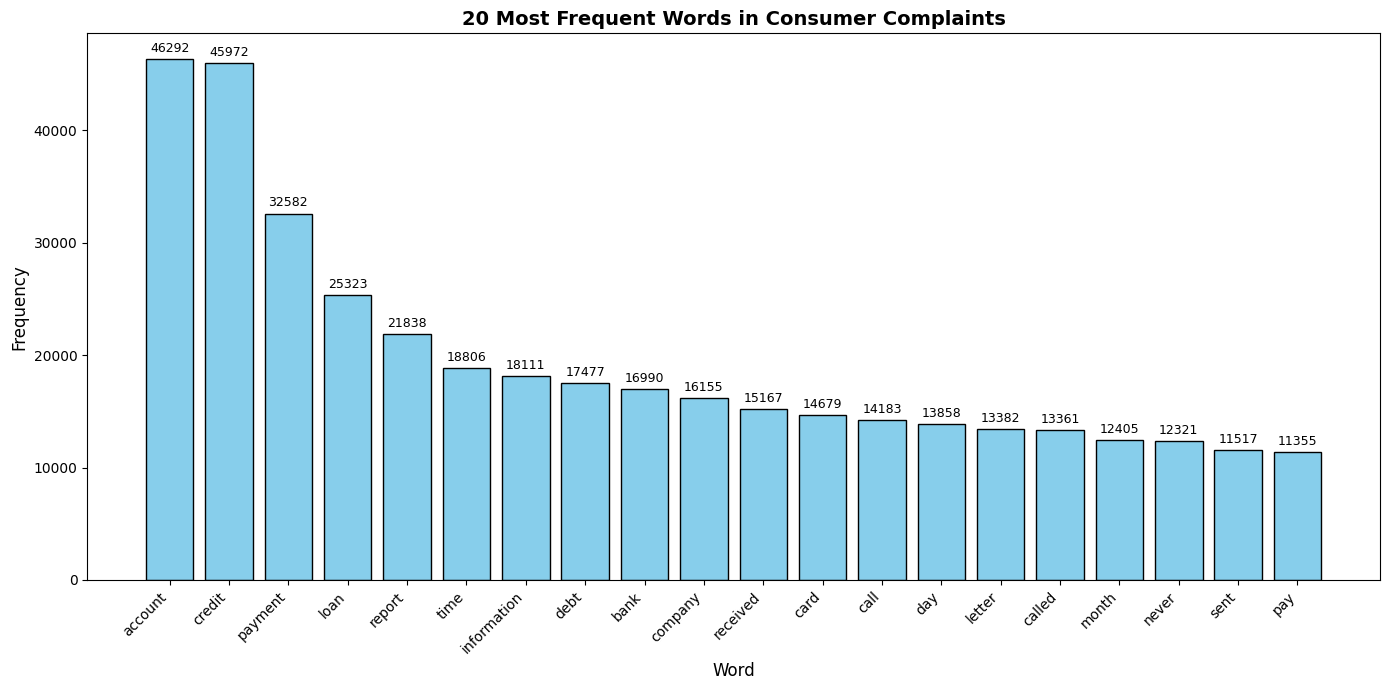

In [21]:
plt.figure(figsize=(14, 7))

bars = plt.bar(
    top_words["Word"],
    top_words["Frequency"],
    color="skyblue",
    edgecolor="black"
)

plt.bar_label(bars, padding=3, fmt='%d', fontsize=9)

plt.title("20 Most Frequent Words in Consumer Complaints", fontsize=14, fontweight="bold")
plt.xlabel("Word", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

# **Word cloud**

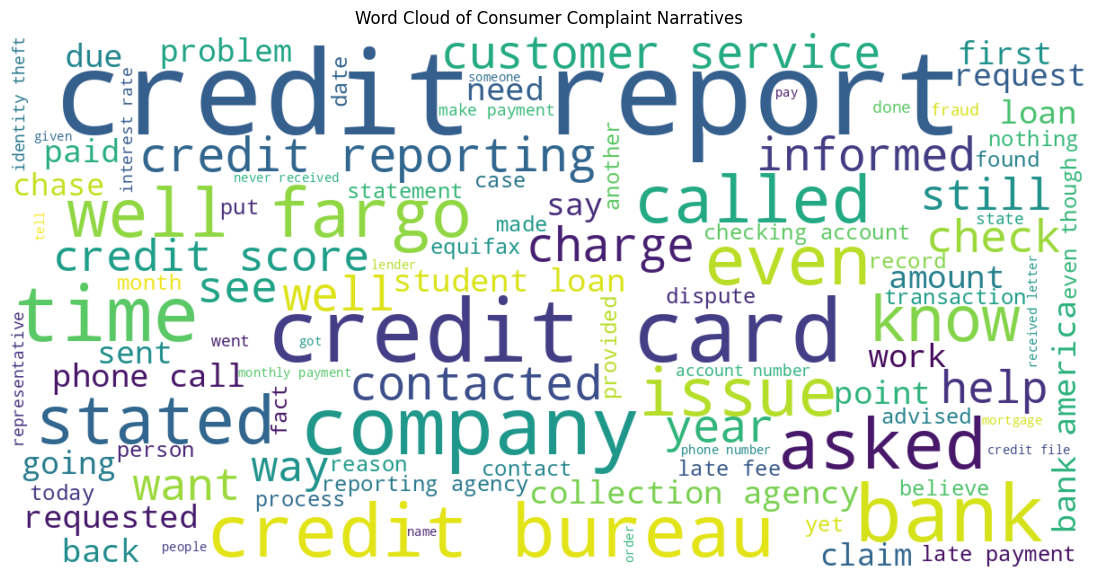

In [22]:
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(" ".join(data["clean_text"]))

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Consumer Complaint Narratives")
plt.show()

# **Bag-of-Words Feature Extraction**

In [23]:
bow_vectorizer = CountVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

bow_matrix = bow_vectorizer.fit_transform(data["clean_text"])

print("BAG-OF-WORDS RESULTS")
print("-" * 50)
print("Documents:", bow_matrix.shape[0])
print("Features:", bow_matrix.shape[1])
print("Matrix shape:", bow_matrix.shape)
print("Non-zero values:", bow_matrix.nnz)

BAG-OF-WORDS RESULTS
--------------------------------------------------
Documents: 29999
Features: 5000
Matrix shape: (29999, 5000)
Non-zero values: 1919303


# **Top 20 Most Frequent Bag-of-Words Terms**

In [24]:
bow_terms = bow_vectorizer.get_feature_names_out()

bow_frequencies = np.asarray(
    bow_matrix.sum(axis=0)
).ravel()

bow_top = pd.DataFrame({
    "Term": bow_terms,
    "Frequency": bow_frequencies
}).sort_values(
    "Frequency",
    ascending=False
).head(20)

bow_top.reset_index(drop=True)

,Term,Frequency
0,account,46292
1,credit,45972
2,payment,32582
3,loan,25323
4,report,21838
5,time,18806
6,information,18111
7,debt,17477
8,bank,16990
9,company,16155


# **TF-IDF Feature Extraction and Text Vectorization**

In [25]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    data["clean_text"]
)

print("TF-IDF RESULTS")
print("-" * 50)
print("Documents:", tfidf_matrix.shape[0])
print("Features:", tfidf_matrix.shape[1])
print("Matrix shape:", tfidf_matrix.shape)
print("Non-zero values:", tfidf_matrix.nnz)

TF-IDF RESULTS
--------------------------------------------------
Documents: 29999
Features: 5000
Matrix shape: (29999, 5000)
Non-zero values: 1919303


# **TF-IDF vs Bag of Words Vectorization Comparison**

In [26]:
bow_density = bow_matrix.nnz / (
    bow_matrix.shape[0] * bow_matrix.shape[1]
)

tfidf_density = tfidf_matrix.nnz / (
    tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
)

vectorization_comparison = pd.DataFrame({
    "Method": ["Bag of Words", "TF-IDF"],
    "Documents": [
        bow_matrix.shape[0],
        tfidf_matrix.shape[0]
    ],
    "Features": [
        bow_matrix.shape[1],
        tfidf_matrix.shape[1]
    ],
    "Non-zero values": [
        bow_matrix.nnz,
        tfidf_matrix.nnz
    ],
    "Matrix density": [
        bow_density,
        tfidf_density
    ]
})

vectorization_comparison

,Method,Documents,Features,Non-zero values,Matrix density
0,Bag of Words,29999,5000,1919303,0.012796
1,TF-IDF,29999,5000,1919303,0.012796


# **Latent Dirichlet Allocation (LDA) Topic Modeling**

In [27]:
n_topics = 5

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=10,
    n_jobs=-1
)

lda_document_topics = lda_model.fit_transform(
    bow_matrix
)

print("LDA training completed.")
print("Document-topic matrix shape:",
      lda_document_topics.shape)

LDA training completed.
Document-topic matrix shape: (29999, 5)


# **Extraction and Visualization of LDA Topic Keywords**

In [28]:
def extract_topics(model, feature_names, n_words=10):

    topic_data = []

    for topic_number, topic in enumerate(model.components_):

        top_indices = topic.argsort()[-n_words:][::-1]

        top_terms = [
            feature_names[i]
            for i in top_indices
        ]

        topic_data.append({
            "Topic": f"Topic {topic_number + 1}",
            "Top terms": ", ".join(top_terms)
        })

    return pd.DataFrame(topic_data)


lda_topics_table = extract_topics(
    lda_model,
    bow_vectorizer.get_feature_names_out(),
    10
)

lda_topics_table

,Topic,Top terms
0,Topic 1,"loan, mortgage, home, document, modification, property, year, time, information, sale"
1,Topic 2,"credit, account, report, debt, credit report, information, reporting, collection, letter, company"
2,Topic 3,"card, call, credit, called, phone, time, number, credit card, back, company"
3,Topic 4,"payment, loan, credit, month, late, time, due, paid, pay, interest"
4,Topic 5,"account, bank, fee, check, payment, money, day, received, well, fund"


# **Distribution Analysis of Dominant LDA Topics**

In [29]:
lda_dominant_topic = np.argmax(
    lda_document_topics,
    axis=1
)

data["LDA_topic"] = lda_dominant_topic + 1

lda_distribution = (
    data["LDA_topic"]
    .value_counts()
    .sort_index()
)

lda_percent = (
    lda_distribution / len(data) * 100
).round(2)

lda_summary = pd.DataFrame({
    "Topic": [
        f"Topic {i}"
        for i in lda_distribution.index
    ],
    "Complaints": lda_distribution.values,
    "Percentage": lda_percent.values
})

lda_summary

,Topic,Complaints,Percentage
0,Topic 1,3557,11.86
1,Topic 2,10194,33.98
2,Topic 3,7372,24.57
3,Topic 4,5066,16.89
4,Topic 5,3810,12.70


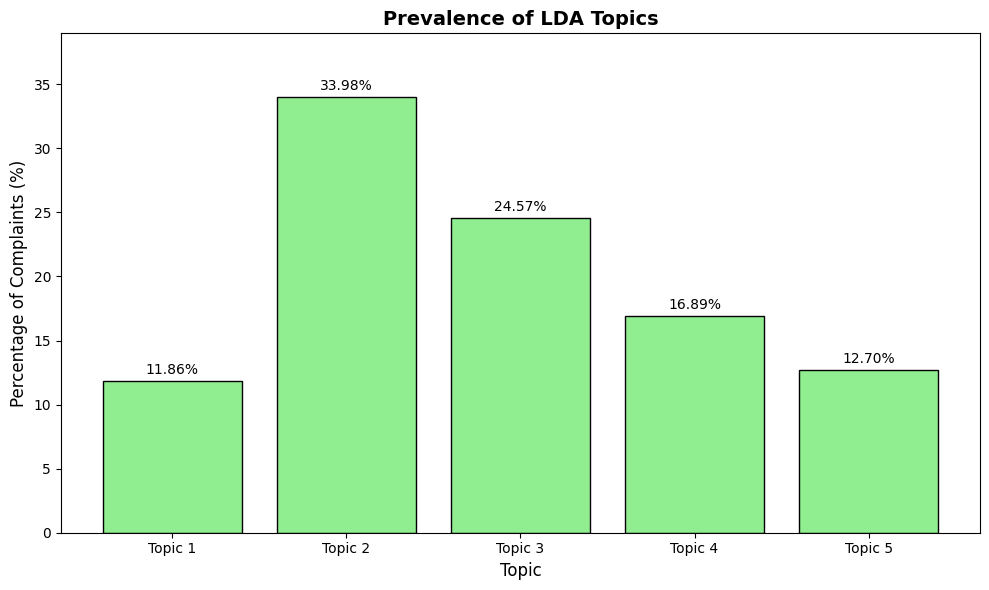

In [30]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    lda_summary["Topic"],
    lda_summary["Percentage"],
    color="lightgreen",
    edgecolor="black"
)

plt.bar_label(bars, padding=3, fmt='%.2f%%', fontsize=10)

plt.title("Prevalence of LDA Topics", fontsize=14, fontweight="bold")
plt.xlabel("Topic", fontsize=12)
plt.ylabel("Percentage of Complaints (%)", fontsize=12)
plt.ylim(0, max(lda_summary["Percentage"]) + 5)
plt.tight_layout()
plt.show()

# **LDA Model Evaluation Using Perplexity Score**

In [31]:
lda_perplexity = lda_model.perplexity(bow_matrix)

print("LDA Perplexity:", round(lda_perplexity, 2))

LDA Perplexity: 1229.61


# **Non-Negative Matrix Factorization (NMF) Topic Modeling**

In [32]:
nmf_model = NMF(
    n_components=n_topics,
    init="nndsvda",
    random_state=42,
    max_iter=400
)

nmf_document_topics = nmf_model.fit_transform(
    tfidf_matrix
)

print("NMF training completed.")
print("Document-topic matrix shape:",
      nmf_document_topics.shape)

NMF training completed.
Document-topic matrix shape: (29999, 5)


# **Extraction of Top Keywords from NMF Topics**

In [33]:
nmf_topics_table = extract_topics(
    nmf_model,
    tfidf_vectorizer.get_feature_names_out(),
    10
)

nmf_topics_table

,Topic,Top terms
0,Topic 1,"account, card, bank, credit card, fee, charge, check, credit, chase, balance"
1,Topic 2,"credit, report, credit report, inquiry, reporting, account, information, equifax, removed, bureau"
2,Topic 3,"debt, collection, agency, collection agency, letter, collect, validation, company, owe, original"
3,Topic 4,"payment, loan, mortgage, late, interest, month, pay, year, due, modification"
4,Topic 5,"call, phone, number, called, time, back, company, calling, asked, information"


# **Distribution Analysis of Dominant NMF Topics**

In [34]:
nmf_dominant_topic = np.argmax(
    nmf_document_topics,
    axis=1
)

data["NMF_topic"] = nmf_dominant_topic + 1

nmf_distribution = (
    data["NMF_topic"]
    .value_counts()
    .sort_index()
)

nmf_percent = (
    nmf_distribution / len(data) * 100
).round(2)

nmf_summary = pd.DataFrame({
    "Topic": [
        f"Topic {i}"
        for i in nmf_distribution.index
    ],
    "Complaints": nmf_distribution.values,
    "Percentage": nmf_percent.values
})

nmf_summary

,Topic,Complaints,Percentage
0,Topic 1,4954,16.51
1,Topic 2,7851,26.17
2,Topic 3,4172,13.91
3,Topic 4,6899,23.00
4,Topic 5,6123,20.41


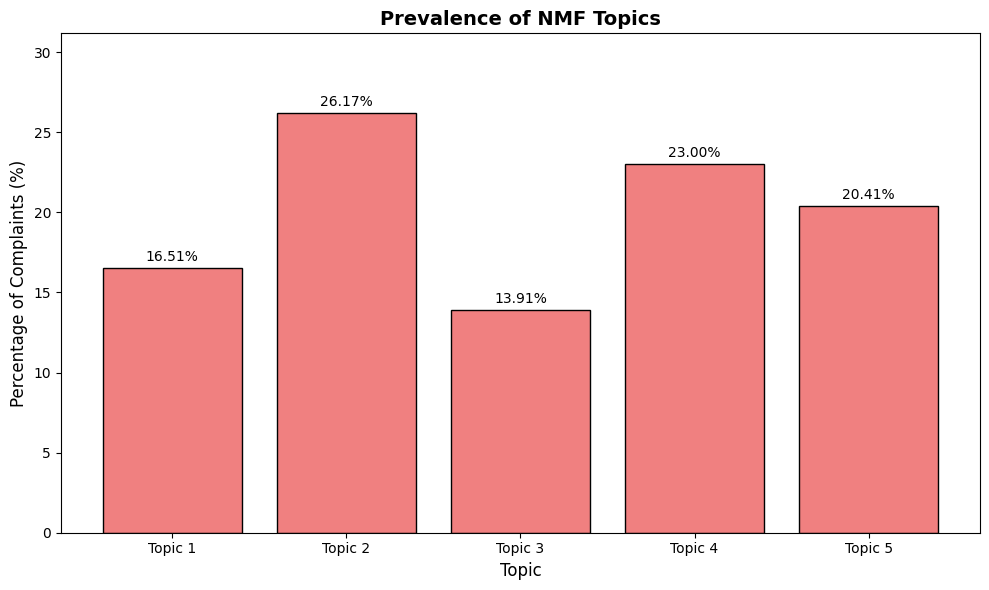

In [35]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    nmf_summary["Topic"],
    nmf_summary["Percentage"],
    color="lightcoral",
    edgecolor="black"
)

plt.bar_label(bars, padding=3, fmt='%.2f%%', fontsize=10)

plt.title("Prevalence of NMF Topics", fontsize=14, fontweight="bold")
plt.xlabel("Topic", fontsize=12)
plt.ylabel("Percentage of Complaints (%)", fontsize=12)
plt.ylim(0, max(nmf_summary["Percentage"]) + 5)
plt.tight_layout()
plt.show()

# **Comparative Summary of LDA and NMF Topic Modeling Results**

In [36]:
print("=" * 80)
print("LDA TOPICS")
print("=" * 80)

display(lda_topics_table)

print("\n")
print("=" * 80)
print("NMF TOPICS")
print("=" * 80)

display(nmf_topics_table)

print("\n")
print("=" * 80)
print("TOPIC PREVALENCE - LDA")
print("=" * 80)

display(lda_summary)

print("\n")
print("=" * 80)
print("TOPIC PREVALENCE - NMF")
print("=" * 80)

display(nmf_summary)

LDA TOPICS


,Topic,Top terms
0,Topic 1,"loan, mortgage, home, document, modification, property, year, time, information, sale"
1,Topic 2,"credit, account, report, debt, credit report, information, reporting, collection, letter, company"
2,Topic 3,"card, call, credit, called, phone, time, number, credit card, back, company"
3,Topic 4,"payment, loan, credit, month, late, time, due, paid, pay, interest"
4,Topic 5,"account, bank, fee, check, payment, money, day, received, well, fund"




NMF TOPICS


,Topic,Top terms
0,Topic 1,"account, card, bank, credit card, fee, charge, check, credit, chase, balance"
1,Topic 2,"credit, report, credit report, inquiry, reporting, account, information, equifax, removed, bureau"
2,Topic 3,"debt, collection, agency, collection agency, letter, collect, validation, company, owe, original"
3,Topic 4,"payment, loan, mortgage, late, interest, month, pay, year, due, modification"
4,Topic 5,"call, phone, number, called, time, back, company, calling, asked, information"




TOPIC PREVALENCE - LDA


,Topic,Complaints,Percentage
0,Topic 1,3557,11.86
1,Topic 2,10194,33.98
2,Topic 3,7372,24.57
3,Topic 4,5066,16.89
4,Topic 5,3810,12.70




TOPIC PREVALENCE - NMF


,Topic,Complaints,Percentage
0,Topic 1,4954,16.51
1,Topic 2,7851,26.17
2,Topic 3,4172,13.91
3,Topic 4,6899,23.00
4,Topic 5,6123,20.41


In [37]:
!pip install -q gensim


from gensim.corpora import Dictionary
from gensim.models import CoherenceModel


print("Total cleaned complaints:", len(data))


rng = np.random.default_rng(42)


tuning_size = min(6000, len(data))
tuning_indices = rng.choice(
    len(data), size=tuning_size, replace=False
)

bow_tuning = bow_matrix[tuning_indices]
tfidf_tuning = tfidf_matrix[tuning_indices]


evaluation_size = min(2000, tuning_size)
evaluation_indices = tuning_indices[:evaluation_size]


analyzer = bow_vectorizer.build_analyzer()

coherence_texts = [
    analyzer(text)
    for text in data.iloc[evaluation_indices]["clean_text"]
]

coherence_dictionary = Dictionary(coherence_texts)

def get_topic_words(model, vectorizer, top_n=10):
    feature_names = vectorizer.get_feature_names_out()
    topics = []

    for component in model.components_:
        top_indices = component.argsort()[-top_n:][::-1]
        topics.append(
            [feature_names[i] for i in top_indices]
        )

    return topics

def calculate_coherence(model, vectorizer):
    topics = get_topic_words(model, vectorizer)


    missing_terms = {
        word
        for topic in topics
        for word in topic
        if word not in coherence_dictionary.token2id
    }

    if missing_terms:

        print("Missing coherence terms:", missing_terms)
        return np.nan

    coherence_model = CoherenceModel(
        topics=topics,
        texts=coherence_texts,
        dictionary=coherence_dictionary,
        coherence="c_v",
        processes=2
    )

    return coherence_model.get_coherence()

print("Coherence evaluation setup completed.")
print("Tuning documents:", tuning_size)
print("Evaluation documents:", evaluation_size)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 71.4 MB/s eta 0:00:00
Total cleaned complaints: 29999
Coherence evaluation setup completed.
Tuning documents: 6000
Evaluation documents: 2000



Evaluating 3 topics...
LDA coherence: 0.7252
NMF coherence: 0.6960

Evaluating 4 topics...
LDA coherence: 0.7203
NMF coherence: 0.6885

Evaluating 5 topics...
LDA coherence: 0.7030
NMF coherence: 0.6533

Evaluating 6 topics...
LDA coherence: 0.6784
NMF coherence: 0.6404

Evaluating 7 topics...
LDA coherence: 0.6826
NMF coherence: 0.6566

Evaluating 8 topics...
LDA coherence: 0.6853
NMF coherence: 0.6712

COHERENCE COMPARISON RESULTS


,Model,Number of Topics,Coherence Score
0,LDA,3,0.7252
1,NMF,3,0.6960
2,LDA,4,0.7203
3,NMF,4,0.6885
4,LDA,5,0.7030
5,NMF,5,0.6533
6,LDA,6,0.6784
7,NMF,6,0.6404
8,LDA,7,0.6826
9,NMF,7,0.6566


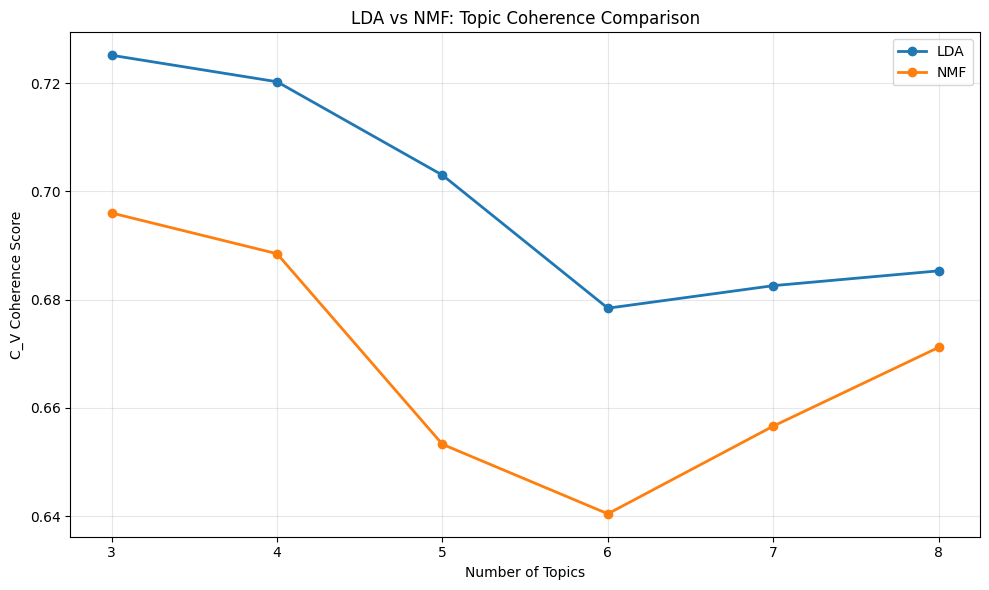


BEST TESTED CONFIGURATION
Model: LDA
Number of topics: 3
Tuning coherence: 0.7252


In [38]:
topic_range = range(3, 9)

coherence_results = []

for k in topic_range:

    print(f"\nEvaluating {k} topics...")

    lda_test = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
        n_jobs=2
    )

    lda_test.fit(bow_tuning)

    lda_coherence = calculate_coherence(
        lda_test, bow_vectorizer
    )

    coherence_results.append({
        "Model": "LDA",
        "Number of Topics": k,
        "Coherence Score": lda_coherence
    })

    nmf_test = NMF(
        n_components=k,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    nmf_test.fit(tfidf_tuning)

    nmf_coherence = calculate_coherence(
        nmf_test, tfidf_vectorizer
    )

    coherence_results.append({
        "Model": "NMF",
        "Number of Topics": k,
        "Coherence Score": nmf_coherence
    })

    print(f"LDA coherence: {lda_coherence:.4f}")
    print(f"NMF coherence: {nmf_coherence:.4f}")

coherence_df = pd.DataFrame(coherence_results)

print("\nCOHERENCE COMPARISON RESULTS")
display(coherence_df.round(4))

plt.figure(figsize=(10, 6))

for model_name in ["LDA", "NMF"]:
    subset = coherence_df[
        coherence_df["Model"] == model_name
    ]

    plt.plot(
        subset["Number of Topics"],
        subset["Coherence Score"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Number of Topics")
plt.ylabel("C_V Coherence Score")
plt.title("LDA vs NMF: Topic Coherence Comparison")
plt.xticks(list(topic_range))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

valid_results = coherence_df.dropna(
    subset=["Coherence Score"]
)

if valid_results.empty:
    raise ValueError(
        "No valid coherence scores. "
        "Increase the evaluation sample size."
    )

best_row = valid_results.loc[
    valid_results["Coherence Score"].idxmax()
]

best_model_name = best_row["Model"]
best_k = int(best_row["Number of Topics"])
best_tuning_score = best_row["Coherence Score"]

print("\nBEST TESTED CONFIGURATION")
print("Model:", best_model_name)
print("Number of topics:", best_k)
print("Tuning coherence:", round(best_tuning_score, 4))


Final selected model: LDA
Selected number of topics: 3

FINAL TOP TOPICS IDENTIFIED


,Rank,Topic,Top Keywords,Complaint Count,Percentage (%)
0,1,Topic 2,"credit, report, account, debt, information, credit report, reporting, collection, company, letter",11647,38.82
1,2,Topic 3,"account, card, payment, call, bank, called, credit, time, day, received",11618,38.73
2,3,Topic 1,"loan, payment, mortgage, time, home, year, month, bank, interest, amount",6734,22.45



FINAL MODEL EVALUATION
Selected model: LDA
Number of topics: 3
Final C_V coherence: 0.7222
Complaints analysed: 29999


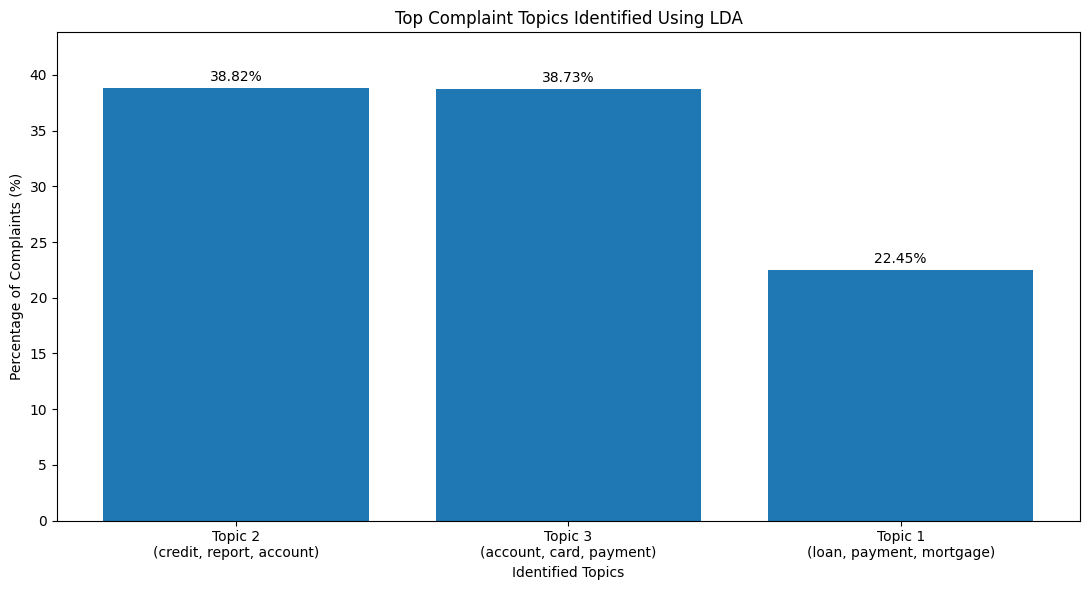


Results exported successfully.


In [39]:
print("Final selected model:", best_model_name)
print("Selected number of topics:", best_k)

if best_model_name == "LDA":

    final_model = LatentDirichletAllocation(
        n_components=best_k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
        n_jobs=2
    )

    final_document_topics = final_model.fit_transform(
        bow_matrix
    )

    final_vectorizer = bow_vectorizer

else:

    final_model = NMF(
        n_components=best_k,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    final_document_topics = final_model.fit_transform(
        tfidf_matrix
    )

    final_vectorizer = tfidf_vectorizer

final_coherence = calculate_coherence(
    final_model, final_vectorizer
)

final_topic_words = get_topic_words(
    final_model, final_vectorizer, top_n=10
)

dominant_topics = np.argmax(
    final_document_topics, axis=1
)

topic_counts = np.bincount(
    dominant_topics, minlength=best_k
)

final_topic_overview = pd.DataFrame({
    "Topic": [
        f"Topic {i+1}" for i in range(best_k)
    ],
    "Top Keywords": [
        ", ".join(words)
        for words in final_topic_words
    ],
    "Complaint Count": topic_counts,
    "Percentage (%)": (
        topic_counts / len(data) * 100
    ).round(2)
})

final_topic_overview = (
    final_topic_overview
    .sort_values(
        "Complaint Count", ascending=False
    )
    .reset_index(drop=True)
)

final_topic_overview.insert(
    0,
    "Rank",
    range(1, len(final_topic_overview) + 1)
)

print("\nFINAL TOP TOPICS IDENTIFIED")
display(final_topic_overview)

print("\nFINAL MODEL EVALUATION")
print("Selected model:", best_model_name)
print("Number of topics:", best_k)
print("Final C_V coherence:", round(final_coherence, 4))
print("Complaints analysed:", len(data))

plt.figure(figsize=(11, 6))

bar_labels = [
    f"{t}\n({', '.join(k.split(', ')[:3])})"
    for t, k in zip(
        final_topic_overview["Topic"],
        final_topic_overview["Top Keywords"]
    )
]

bars = plt.bar(
    bar_labels,
    final_topic_overview["Percentage (%)"]
)

plt.bar_label(
    bars, fmt="%.2f%%", padding=3
)

plt.xlabel("Identified Topics")
plt.ylabel("Percentage of Complaints (%)")
plt.title(
    f"Top Complaint Topics Identified Using {best_model_name}"
)

plt.ylim(
    0,
    final_topic_overview["Percentage (%)"].max() + 5
)

plt.tight_layout()
plt.show()

coherence_df.to_csv(
    "coherence_comparison.csv", index=False
)

final_topic_overview.to_csv(
    "final_topic_overview.csv", index=False
)

print("\nResults exported successfully.")


# **Validation of Topics Against the Product Column**


In [40]:
# Recover the Product label for each analysed complaint
product_map = (
    df.dropna(subset=[text_column])
      .drop_duplicates(subset=[text_column])
      .set_index(text_column)["Product"]
)

data["Product"] = data[text_column].map(product_map)
data["Final_topic"] = [f"Topic {t + 1}" for t in dominant_topics]

print("Complaints with Product label:", data["Product"].notna().sum())

# Share of each Product within each final topic (%)
topic_product = (
    pd.crosstab(data["Final_topic"], data["Product"], normalize="index")
      .mul(100)
      .round(2)
)

rows = []
for topic in final_topic_overview["Topic"]:
    top3 = topic_product.loc[topic].sort_values(ascending=False).head(3)
    rows.append({
        "Topic": topic,
        "Complaints": int((data["Final_topic"] == topic).sum()),
        "Top Product 1": f"{top3.index[0]} ({top3.iloc[0]:.1f}%)",
        "Top Product 2": f"{top3.index[1]} ({top3.iloc[1]:.1f}%)",
        "Top Product 3": f"{top3.index[2]} ({top3.iloc[2]:.1f}%)",
    })

topic_product_check = pd.DataFrame(rows)

print("\nTOPIC vs PRODUCT CHECK")
display(topic_product_check)

topic_product_check.to_csv("topic_product_check.csv", index=False)

Complaints with Product label: 29999

TOPIC vs PRODUCT CHECK


,Topic,Complaints,Top Product 1,Top Product 2,Top Product 3
0,Topic 2,11647,"Credit reporting, credit repair services, or other personal consumer reports (44.4%)",Debt collection (31.5%),Credit reporting (17.2%)
1,Topic 3,11618,Debt collection (23.4%),Credit card or prepaid card (13.6%),Credit card (11.3%)
2,Topic 1,6734,Mortgage (53.7%),Student loan (22.2%),Debt collection (6.4%)
